# Ein kleiner Transformer lernt deutsche Geschichten

**Ziel:** Wir trainieren einen kleinen Transformer von Grund auf und beobachten, wie sich seine Textfortsetzungen verändern: **vor dem Training**, nach einigen Updates und am Ende.

Als Daten verwenden wir die 1.000 kurzen deutschen Geschichten aus [Mediform/tiny-stories-de](https://huggingface.co/datasets/Mediform/tiny-stories-de). Die Texte sind Übersetzungen synthetischer TinyStories; manche Formulierungen sind etwas holprig. Wir nutzen nur die Spalte `text`.

Das Modell sagt immer **das nächste Zeichen** voraus. Durch wiederholtes Anhängen entsteht eine längere Sequenz. Es gibt kein vortrainiertes Sprachwissen.

Alle Zellen der Reihe nach ausführen. Beim ersten Lauf ist Internet für den Datensatz nötig. Eine GPU ist hilfreich; CPU funktioniert ebenfalls, dauert aber länger. Die tatsächliche Laufzeit wird während des Trainings angezeigt.


In [ ]:
# Einmalig im aktuellen Notebook-Kernel installieren; danach ggf. Kernel neu starten.
%pip install torch datasets matplotlib


## 1. Einstellungen

Wir beschränken uns auf zwei Transformerblöcke. Ein Token ist hier ein Zeichen, auch ein Leerzeichen oder ein Umlaut. Das Kontextfenster enthält die letzten 128 Zeichen.

Für einen kurzen Probelauf `TRAIN_STEPS = 100` setzen. Für deutlichere Sprachmuster sind eher einige Tausend Updates nötig. Die Qualität hängt von Trainingsdauer und Modellgröße ab; perfekte Geschichten sind nicht das Ziel.


In [ ]:
import math
import time
import textwrap

import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset

SEED = 42
CONTEXT_LENGTH = 128
BATCH_SIZE = 32
EMBED_DIM = 96
NUM_HEADS = 4
NUM_LAYERS = 2
TRAIN_STEPS = 2000
SHOW_EVERY = 250
LEARNING_RATE = 1e-3
NEW_CHARS = 220
TEMPERATURE = 0.8

# Automatisch GPU verwenden, falls vorhanden.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
# Kleine Modelle sind auf CPU mit wenigen Threads oft schneller.
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
torch.manual_seed(SEED)
print("Gerät:", device)


## 2. Geschichten laden und in Zahlen übersetzen

Wir trennen **ganze Geschichten** in 90 % Training und 10 % Validierung. Dadurch landen überlappende Ausschnitte derselben Geschichte nicht in beiden Mengen. Das Zeichenvokabular wird aus den Trainingsgeschichten aufgebaut; seltene unbekannte Zeichen der Validierung erhalten ein eigenes Token.


In [3]:
dataset = load_dataset("Mediform/tiny-stories-de", split="train")
stories = dataset.train_test_split(test_size=0.1, seed=SEED)
train_text = "\n\n".join(stories["train"]["text"])
val_text = "\n\n".join(stories["test"]["text"])

# ID 0 ist für unbekannte Zeichen reserviert.
characters = sorted(set(train_text))
stoi = {char: i + 1 for i, char in enumerate(characters)}
itos = {i: char for char, i in stoi.items()}
itos[0] = "�"
vocab_size = len(itos)

def encode(text):
    return [stoi.get(char, 0) for char in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)
assert min(len(train_data), len(val_data)) > CONTEXT_LENGTH

print(f"Geschichten: {len(stories['train'])} Training / {len(stories['test'])} Validierung")
print(f"Zeichen: {len(train_data):,} Training / {len(val_data):,} Validierung")
print(f"Vokabular: {vocab_size} Tokens (einschließlich unbekanntem Zeichen)")
print("\nEine Trainingsgeschichte:\n")
print(textwrap.fill(stories["train"][0]["text"], width=100))


completion-de.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Geschichten: 900 Training / 100 Validierung
Zeichen: 872,805 Training / 101,564 Validierung
Vokabular: 75 Tokens (einschließlich unbekanntem Zeichen)

Eine Trainingsgeschichte:

Eines Tages ging ein kleines Mädchen namens Sue in den Park. Sie sah einen großen Baum mit
hellvioletten Blumen. Sue bemerkte, dass einige der Blumen zu Pflaumen geworden waren. Sie wollte
ein paar Pflaumen mit nach Hause nehmen. Sue kletterte auf den Baum und pflückte ein paar Pflaumen.
Sie steckte sie in ihre Tasche. Dann hörte sie eine kleine Stimme sagen: "Hey, das sind meine
Pflaumen!" Sue schaute sich um und sah einen winzigen Vogel auf einem Ast sitzen. Sue sagte: "Es tut
mir leid. Ich wusste nicht, dass es deine Pflaumen sind." Der Vogel sagte: "Das ist in Ordnung. Du
kannst ein paar haben, aber du musst mir zuerst helfen." Das Vogelnest war auf den Boden gefallen.
Sue half dem Vogel, das Nest wieder in den Baum zu legen. Dann durfte Sue ein paar Pflaumen mit nach
Hause nehmen.


In [14]:
len(stories["train"])

900

In [23]:
stories["train"][0]

{'text': 'Eines Tages ging ein kleines Mädchen namens Sue in den Park. Sie sah einen großen Baum mit hellvioletten Blumen. Sue bemerkte, dass einige der Blumen zu Pflaumen geworden waren. Sie wollte ein paar Pflaumen mit nach Hause nehmen.\nSue kletterte auf den Baum und pflückte ein paar Pflaumen. Sie steckte sie in ihre Tasche. Dann hörte sie eine kleine Stimme sagen: "Hey, das sind meine Pflaumen!" Sue schaute sich um und sah einen winzigen Vogel auf einem Ast sitzen.\nSue sagte: "Es tut mir leid. Ich wusste nicht, dass es deine Pflaumen sind." Der Vogel sagte: "Das ist in Ordnung. Du kannst ein paar haben, aber du musst mir zuerst helfen." Das Vogelnest war auf den Boden gefallen. Sue half dem Vogel, das Nest wieder in den Baum zu legen. Dann durfte Sue ein paar Pflaumen mit nach Hause nehmen.',
 'instruction': {'prompt': 'Übersetze den folgenden Text nach Deutsch. Nutze dabei eine für Kinder übliche Sprache.\n\nOne day, a little girl named Sue went to the park. She saw a big tree 

In [24]:
len(train_text)

872805

In [28]:
print(train_text[:2000])

Eines Tages ging ein kleines Mädchen namens Sue in den Park. Sie sah einen großen Baum mit hellvioletten Blumen. Sue bemerkte, dass einige der Blumen zu Pflaumen geworden waren. Sie wollte ein paar Pflaumen mit nach Hause nehmen.
Sue kletterte auf den Baum und pflückte ein paar Pflaumen. Sie steckte sie in ihre Tasche. Dann hörte sie eine kleine Stimme sagen: "Hey, das sind meine Pflaumen!" Sue schaute sich um und sah einen winzigen Vogel auf einem Ast sitzen.
Sue sagte: "Es tut mir leid. Ich wusste nicht, dass es deine Pflaumen sind." Der Vogel sagte: "Das ist in Ordnung. Du kannst ein paar haben, aber du musst mir zuerst helfen." Das Vogelnest war auf den Boden gefallen. Sue half dem Vogel, das Nest wieder in den Baum zu legen. Dann durfte Sue ein paar Pflaumen mit nach Hause nehmen.

Eines Tages hatten ein großer Hund und eine kleine Katze ein Rennen. Der große Hund war sehr wettbewerbsfähig. Er wollte gewinnen. Die kleine Katze wollte einfach nur Spaß haben. Sie rannten und rannten

In [36]:
characters = sorted(set(train_text))
print("characters:", characters)
stoi = {char: i + 1 for i, char in enumerate(characters)}
print("stoi:", stoi)
itos = {i: char for char, i in stoi.items()}
itos[0] = "�"
print("itos:", itos)
vocab_size = len(itos)
print(f"{vocab_size=}")

characters: ['\n', ' ', '!', '"', "'", '*', ',', '-', '.', '0', '1', '3', '4', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', 'Ä', 'Ö', 'Ü', 'ß', 'ä', 'ö', 'ü']
stoi: {'\n': 1, ' ': 2, '!': 3, '"': 4, "'": 5, '*': 6, ',': 7, '-': 8, '.': 9, '0': 10, '1': 11, '3': 12, '4': 13, ':': 14, ';': 15, '?': 16, 'A': 17, 'B': 18, 'C': 19, 'D': 20, 'E': 21, 'F': 22, 'G': 23, 'H': 24, 'I': 25, 'J': 26, 'K': 27, 'L': 28, 'M': 29, 'N': 30, 'O': 31, 'P': 32, 'Q': 33, 'R': 34, 'S': 35, 'T': 36, 'U': 37, 'V': 38, 'W': 39, 'Y': 40, 'Z': 41, 'a': 42, 'b': 43, 'c': 44, 'd': 45, 'e': 46, 'f': 47, 'g': 48, 'h': 49, 'i': 50, 'j': 51, 'k': 52, 'l': 53, 'm': 54, 'n': 55, 'o': 56, 'p': 57, 'q': 58, 'r': 59, 's': 60, 't': 61, 'u': 62, 'v': 63, 'w': 64, 'x': 65, 'y': 66, 'z': 67, 'Ä': 68, 'Ö': 

In [40]:
type(train_data)

torch.Tensor

In [41]:
train_data.shape, train_data.ndim

(torch.Size([872805]), 1)

In [38]:
len(train_data)

872805

In [39]:
len(train_text)

872805

## 3. Die Lernaufgabe: um ein Zeichen verschieben

Aus einem Textausschnitt machen wir Eingabe und Ziel. Zum Beispiel:

```text
Eingabe: T i m ␣ g e h
Ziel:    i m ␣ g e h t
```

An **jeder Position** soll das Modell das nächste Zeichen vorhersagen. Eine kausale Attention-Maske verhindert, dass es dabei zukünftige Zeichen der Eingabe anschaut.


In [42]:
# Eigener Zufallsgenerator: Auswertungen verändern die Trainingsausschnitte nicht.
batch_rng = torch.Generator().manual_seed(SEED)

def get_batch(data, generator=batch_rng):
    starts = torch.randint(
        len(data) - CONTEXT_LENGTH, (BATCH_SIZE,), generator=generator
    )
    x = torch.stack([data[i:i + CONTEXT_LENGTH] for i in starts.tolist()])
    y = torch.stack([data[i + 1:i + CONTEXT_LENGTH + 1] for i in starts.tolist()])
    return x.to(device), y.to(device)

x_demo, y_demo = get_batch(train_data, torch.Generator().manual_seed(0))
print("Eingabe:", repr(decode(x_demo[0, :60].tolist())))
print("Ziel:   ", repr(decode(y_demo[0, :60].tolist())))
print("Batchform:", tuple(x_demo.shape), "= (Ausschnitte, Zeichen)")


Eingabe: 'ch."\nIhre Mama umarmte sie und sagte: "Danke, Lily. Du bist '
Ziel:    'h."\nIhre Mama umarmte sie und sagte: "Danke, Lily. Du bist a'
Batchform: (32, 128) = (Ausschnitte, Zeichen)


In [44]:
type(x_demo), x_demo.shape

(torch.Tensor, torch.Size([32, 128]))

In [45]:
x_demo

tensor([[44, 49,  9,  ..., 46,  2, 31],
        [54, 54, 46,  ..., 53, 46, 55],
        [72, 45, 44,  ..., 61,  7,  2],
        ...,
        [62,  2, 60,  ..., 48, 46, 55],
        [61, 46,  2,  ..., 35, 50, 46],
        [50, 55, 47,  ..., 53, 47, 53]], device='cuda:0')

In [46]:
x_demo[0]

tensor([44, 49,  9,  4,  1, 25, 49, 59, 46,  2, 29, 42, 54, 42,  2, 62, 54, 42,
        59, 54, 61, 46,  2, 60, 50, 46,  2, 62, 55, 45,  2, 60, 42, 48, 61, 46,
        14,  2,  4, 20, 42, 55, 52, 46,  7,  2, 28, 50, 53, 66,  9,  2, 20, 62,
         2, 43, 50, 60, 61,  2, 42, 62, 44, 49,  2, 49, 74, 43, 60, 44, 49,  9,
         2, 37, 55, 45,  2, 45, 62,  2, 43, 50, 60, 61,  2, 60, 46, 49, 59,  2,
        54, 62, 61, 50, 48,  2, 62, 55, 45,  2, 55, 46, 62, 48, 50, 46, 59, 50,
        48,  7,  2, 48, 46, 55, 42, 62,  2, 64, 50, 46,  2, 45, 46, 50, 55, 46,
         2, 31], device='cuda:0')

In [47]:
y_demo[0]

tensor([49,  9,  4,  1, 25, 49, 59, 46,  2, 29, 42, 54, 42,  2, 62, 54, 42, 59,
        54, 61, 46,  2, 60, 50, 46,  2, 62, 55, 45,  2, 60, 42, 48, 61, 46, 14,
         2,  4, 20, 42, 55, 52, 46,  7,  2, 28, 50, 53, 66,  9,  2, 20, 62,  2,
        43, 50, 60, 61,  2, 42, 62, 44, 49,  2, 49, 74, 43, 60, 44, 49,  9,  2,
        37, 55, 45,  2, 45, 62,  2, 43, 50, 60, 61,  2, 60, 46, 49, 59,  2, 54,
        62, 61, 50, 48,  2, 62, 55, 45,  2, 55, 46, 62, 48, 50, 46, 59, 50, 48,
         7,  2, 48, 46, 55, 42, 62,  2, 64, 50, 46,  2, 45, 46, 50, 55, 46,  2,
        31, 54], device='cuda:0')

## 4. Das Modell auf einen Blick

**Zeichen-IDs → Zeichen- und Positionsembeddings → kausale Transformerblöcke → Wahrscheinlichkeiten für das nächste Zeichen**

Self-Attention verknüpft die bisherigen Zeichen; ein kleines Feedforward-Netz verarbeitet die Ergebnisse. PyTorch liefert die fertigen Blöcke. Obwohl die verwendete Klasse `TransformerEncoder` heißt, arbeitet sie hier mit einer kausalen Maske als GPT-artiges Sprachmodell: Es gibt keine Cross-Attention und keinen Zugriff auf zukünftige Zeichen.


In [54]:
class MiniTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, EMBED_DIM)
        self.position_embedding = nn.Embedding(CONTEXT_LENGTH, EMBED_DIM)
        block = nn.TransformerEncoderLayer(
            d_model=EMBED_DIM,
            nhead=NUM_HEADS,
            dim_feedforward=4 * EMBED_DIM,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.blocks = nn.TransformerEncoder(
            block, num_layers=NUM_LAYERS, enable_nested_tensor=False
        )
        self.final_norm = nn.LayerNorm(EMBED_DIM)
        self.output = nn.Linear(EMBED_DIM, vocab_size)
        # True oberhalb der Diagonalen = zukünftige Position ist gesperrt.
        self.register_buffer(
            "causal_mask",
            torch.triu(torch.ones(CONTEXT_LENGTH, CONTEXT_LENGTH, dtype=torch.bool), diagonal=1),
        )
        # Auch die kopierten Transformerblöcke unterschiedlich initialisieren.
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.MultiheadAttention):
            nn.init.xavier_uniform_(module.in_proj_weight)
            nn.init.zeros_(module.in_proj_bias)

    def forward(self, ids):
        length = ids.shape[1]
        positions = torch.arange(length, device=ids.device)
        hidden = self.token_embedding(ids) + self.position_embedding(positions)
        hidden = self.blocks(hidden, mask=self.causal_mask[:length, :length])
        return self.output(self.final_norm(hidden))

model = MiniTransformer().to(device)
parameter_count = sum(p.numel() for p in model.parameters())
print(f"Trainierbare Parameter: {parameter_count:,}")


Trainierbare Parameter: 250,635


In [49]:
vocab_size, EMBED_DIM

(75, 96)

In [52]:
model.token_embedding

Embedding(75, 96)

In [53]:
model.position_embedding

Embedding(128, 96)

## 5. Text erzeugen – zunächst ohne Training

Wir geben einen Starttext vor, berechnen die Verteilung für das nächste Zeichen, ziehen daraus ein Zeichen und hängen es an. Dann wiederholen wir das Ganze. Das Modell sieht jeweils höchstens die letzten `CONTEXT_LENGTH` Zeichen.

Für jeden Zwischenstand verwenden wir dieselben Starttexte, dieselbe Temperatur und denselben Sampling-Seed. So wird die Veränderung durch das Training besser vergleichbar. Temperaturwerte unter 1 bevorzugen wahrscheinlichere Zeichen stärker. Die Zufallsziehung erfolgt auf CPU und funktioniert damit auch bei Nutzung einer MPS-GPU.


In [55]:
@torch.no_grad()
def generate(prompt, new_chars=NEW_CHARS, temperature=TEMPERATURE, seed=123):
    if not prompt:
        raise ValueError("Bitte einen nicht leeren Starttext angeben.")
    if temperature <= 0:
        raise ValueError("Die Temperatur muss positiv sein.")
    unknown = sorted(set(prompt) - set(stoi))
    if unknown:
        raise ValueError(f"Zeichen fehlen im Trainingsvokabular: {unknown}")
    was_training = model.training
    model.eval()  # Dropout für die Textgenerierung ausschalten.
    try:
        ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
        sampling_rng = torch.Generator(device="cpu").manual_seed(seed)
        for _ in range(new_chars):
            logits = model(ids[:, -CONTEXT_LENGTH:])[:, -1, :].clone()
            logits[:, 0] = -torch.inf  # Kein unbekanntes Zeichen generieren.
            probabilities = F.softmax(logits / temperature, dim=-1).cpu()
            next_id = torch.multinomial(probabilities, 1, generator=sampling_rng).to(device)
            ids = torch.cat([ids, next_id], dim=1)
        return decode(ids[0].tolist())
    finally:
        model.train(was_training)

PROMPTS = ["Eines Tages ", "Tim und Lily "]
snapshots = []

def show_predictions(step):
    print(f"\n{'=' * 70}\nNach {step} Trainingsupdates\n{'=' * 70}")
    for prompt in PROMPTS:
        generated = generate(prompt)
        snapshots.append({"step": step, "prompt": prompt, "text": generated})
        print(f"\nStarttext: {prompt!r}\nFortsetzung:")
        print(textwrap.fill(generated[len(prompt):], width=100))

show_predictions(step=0)



Nach 0 Trainingsupdates

Starttext: 'Eines Tages '
Fortsetzung:
 VFzAbOQe;WoZaqSgA3FQ v ÜD0,IÜ3'!3jpRv; Jjuu Nü;*bzßGS-UÄI'3MboFRxL4u3Ys0erNxShKoRmgc--RßE3liJhgBuÄj
*JscQÖ3f,GJ?nntSßi,Jj3yn,sePAbZk?0cltk:oE.*,gmGAEaS'pPPBÜäeqco;iBCjWÄG1jw3.Y'nQxgcQoAZGtJ,nUHÜKFhiÖk
BJj uönÜiQFWhFÜ!ÖgGp

Starttext: 'Tim und Lily '
Fortsetzung:
 VFzAbuQegWoZaqSgA3FQ v ÜD0,I:3'!3jpRv; Jjuu Nü;*bzßGS-UÄI'3MboFRxL4u3Ys0erNxShKoRmgc--RßE3liJHgBuÄV
?JscQÖ3f,GJ?nntSßi,Jj3yn,sePAbZk?CMltk:oE.*,gmGAEaS'pPPBÜäeqco;iBCjWÄG1jw3.Y'nQxgcQoAZGtJ,nUHÜKFhiÖk
BJj uönÜiQFWhFä!ÖgGp


## 6. Trainieren und zwischendurch beobachten

Der **Cross-Entropy-Loss** misst, wie schlecht die Vorhersagen zu den tatsächlichen nächsten Zeichen passen. Kleiner ist besser. Bei einer Gleichverteilung über alle Zeichen läge er bei ungefähr `log(Vokabulargröße)`.

Alle `SHOW_EVERY` Updates messen wir den Loss auf festen Trainings- und Validierungsausschnitten und erzeugen neue Texte. Diese Ausgaben bleiben unter der Zelle stehen. Die Validierung verändert keine Gewichte. Ein Update verarbeitet `BATCH_SIZE` zufällige Ausschnitte und entspricht **keiner vollständigen Epoche**.

Diese Zelle setzt Modell und Optimierer zurück, damit erneutes Ausführen wieder einen vollständigen Vergleich ab Update 0 ergibt.


In [56]:
# Feste Ausschnitte machen die Loss-Werte zwischen Zwischenständen vergleichbar.
@torch.no_grad()
def estimate_loss():
    was_training = model.training
    model.eval()
    results = {}
    try:
        for name, data in [("train", train_data), ("val", val_data)]:
            eval_rng = torch.Generator().manual_seed(2026)
            losses = []
            for _ in range(5):
                x, y = get_batch(data, eval_rng)
                logits = model(x)
                losses.append(F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1)).item())
            results[name] = sum(losses) / len(losses)
        return results
    finally:
        model.train(was_training)

torch.manual_seed(SEED)
batch_rng.manual_seed(SEED)
model = MiniTransformer().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
history = []
snapshots = []
start_time = time.perf_counter()

def report(step):
    losses = estimate_loss()
    history.append({"step": step, **losses})
    elapsed = time.perf_counter() - start_time
    print(f"\nUpdate {step:4d} | Train-Loss {losses['train']:.3f} | "
          f"Val-Loss {losses['val']:.3f} | Zeit {elapsed:.1f} s", flush=True)
    show_predictions(step)

report(0)
model.train()
for step in range(1, TRAIN_STEPS + 1):
    x, y = get_batch(train_data)
    logits = model(x)
    loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    if step % SHOW_EVERY == 0 or step == TRAIN_STEPS:
        report(step)

print(f"\nFertig: {(time.perf_counter() - start_time) / 60:.1f} Minuten.")



Update    0 | Train-Loss 4.292 | Val-Loss 4.290 | Zeit 0.0 s

Nach 0 Trainingsupdates

Starttext: 'Eines Tages '
Fortsetzung:
üVFzAb'Qe;W'ZaqSVA3FQ Z ÜD0,C"3'!3jpRc! Jjuu Nü;*bzßxS-UÄI'sßbäTRxQ4u3Ys0e?NxSbKoRmgc-QRßE3l?JhgBuÄV
*JscQÖTf,GJ?nYtdßi,sj3yn,sePAbZü?0clta:oE.*,g.GAEaS'pPPBTäeqcS;iB0jWÄG1jwd.Y'nQxicpo:ZGaJ,nUTÜKFhiük
BJj  öFaxQFWhFä!ÖgGp

Starttext: 'Tim und Lily '
Fortsetzung:
ÜfFzAbOOegW'ZaqSVY3FQOv ÜD0,I:3'!3jpRc! Jjuu Nü;*bzßxS-UÄI'3ßbäBRxQ4u3Ys0e?NxShKoRUgc-
'RßE3liJhgBuÄV*JscQÖ3f,GJ?n:tdßi,sj3yn,sePAsZü?0cltf:oE.*,g.GAEaS'pPPBTäeqcS;iB0jWÄG1jw3.Y'nQxicpoAZ
GaJ,nUTÜKFhiükBJj uöFaxQFWhFä!ÖgGp

Update  250 | Train-Loss 1.985 | Val-Loss 1.986 | Zeit 1.3 s

Nach 250 Trainingsupdates

Starttext: 'Eines Tages '
Fortsetzung:
ihnzu und so sie As Spielel, eineiner und und Schausen und spiellomnen schtten. Er gen Ruerlinhr und
klchahtterschte ies gyn, ein wüch lte: Ein, mit, Spielline Mamifllllte war sich eine und nin Kah Tom
wer nar derst den

Starttext: 'Tim und Lily '
Fortsetzu

## 7. Lernkurve und direkter Vorher-Nachher-Vergleich

Achte auf Leerzeichen, Wortformen und Satzgrenzen. Verbessert sich auch der Validierungs-Loss? Wenn nur der Trainings-Loss weiter sinkt, kann das ein Hinweis auf Überanpassung sein. Sprachähnlicher Text belegt noch kein inhaltliches Verständnis; einzelne Passagen können aus dem Training übernommen sein.


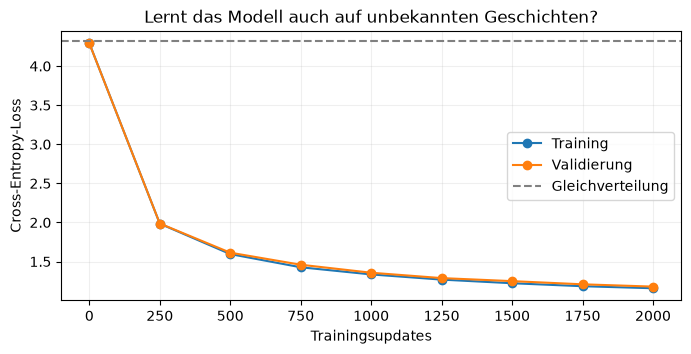


--- Update 0 ---
Eines Tages üVFzAb'Qe;W'ZaqSVA3FQ Z ÜD0,C"3'!3jpRc! Jjuu Nü;*bzßxS-UÄI'sßbäTRxQ4u3Ys0e?NxSbKoRmgc-QR
ßE3l?JhgBuÄV*JscQÖTf,GJ?nYtdßi,sj3yn,sePAbZü?0clta:oE.*,g.GAEaS'pPPBTäeqcS;iB0jWÄG1jwd.Y'nQxicpo:ZGa
J,nUTÜKFhiükBJj  öFaxQFWhFä!ÖgGp

--- Update 250 ---
Eines Tages ihnzu und so sie As Spielel, eineiner und und Schausen und spiellomnen schtten. Er gen
Ruerlinhr und klchahtterschte ies gyn, ein wüch lte: Ein, mit, Spielline Mamifllllte war sich eine
und nin Kah Tom wer nar derst den

--- Update 500 ---
Eines Tages zu zu und so an glück mite nich seinemen und Nach zu hieben. Sie hatten werten immen. Er
war ehr und kleinen, es ntimit sagte ein Zeitelte: "Sam mit annte Baue samit den Bar malle
gefolettzen. Sie ihr Joken annder Tim de

--- Update 750 ---
Eines Tages zu zu fanden an glücklichen, dasse. Sie sah die Katzen und sah Baum und werden immer. Er
war schwurde schaute es nach es gingsein. Sie läfte der mit an dem Tag an ihr und die Nannten und
war sehr hiel Jungen ih

In [57]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot([h["step"] for h in history], [h["train"] for h in history], "o-", label="Training")
ax.plot([h["step"] for h in history], [h["val"] for h in history], "o-", label="Validierung")
ax.axhline(math.log(vocab_size), color="gray", linestyle="--", label="Gleichverteilung")
ax.set(xlabel="Trainingsupdates", ylabel="Cross-Entropy-Loss", title="Lernt das Modell auch auf unbekannten Geschichten?")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

for snapshot in snapshots:
    if snapshot["prompt"] == PROMPTS[0]:
        print(f"\n--- Update {snapshot['step']} ---")
        print(textwrap.fill(snapshot["text"], width=100))


## 8. Selbst ausprobieren

Ändere den Starttext oder die Temperatur und führe die nächste Zelle erneut aus. Eine feste Zufallsinitialisierung macht die Versuche reproduzierbar; andere Seeds erzeugen andere Fortsetzungen.

**Fragen für die Vorlesung:**

- Welche Muster entstehen zuerst: Wörter, Satzzeichen oder inhaltliche Zusammenhänge?
- Was ändert sich bei Temperatur 0.5 gegenüber 1.2?
- Welche Unterschiede sieht man nach 100, 500 und 2.000 Updates?
- Was passiert mit weniger Kontext oder nur einem Transformerblock? Dafür das Notebook ab den Einstellungen erneut ausführen.


In [ ]:
prompt = "Eines Tages fand Tim "
print(generate(prompt, new_chars=400, temperature=0.8, seed=7))
